# 03 — Relating the eta-R9 map change to the efficiency change

Created 2026-10-04. Class: deliverable (plots and numbers for `slides/hlt_2024_etaR9_map_comparison.tex`).

**Question.** The 2024 efficiencies were fitted twice, with the eta-R9 weight map **without NF** and **with NF**. Notebook 02 showed that the weights alone move a counting efficiency by at most 0.0048 while fitted efficiencies move by up to 0.114. This notebook follows the map change through the three stages between "weight" and "fitted efficiency":

1. **map → weighted yields**: how much the map changes the pass and fail yields of each fitter bin (mean change and cell-to-cell spread), from the per-cell probe counts of notebook 01;
2. **weighted yields → mass templates**: the pass / fail mass histograms the fitter actually fitted, without vs with NF: total yield, shape, and a sideband-subtracted efficiency (no fit);
3. **mass templates → fitted yields**: fitted signal and background yields and fit status of every fit, read from the fitter's `*Fit.root` files.

**Inputs** (all local)
- without NF: `/home/santanu/Desktop/HLT_2024_lowmass_final/results/HLT_2024_withPresel[_fullPath]_SS/`
- with NF: `/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/HLT_2024_withPresel[_fullPath]_SS/`
- in each `passingHLT_<leg>_<cat>_2024/`: `*.root` (TH1D `<bin>_Pass`, `<bin>_Fail`, 80 bins, 50–130 GeV) and `*.bwDscb{Cms,Exp}Fit.root` (`RooFitResult` `<bin>_resP`, `<bin>_resF`)
- `data/cell_counts.npz`, `data/counting_vs_fit.csv`, `data/efficiency_three_way.csv` (notebooks 01, 02)

**Outputs**: `data/fit_yields.csv`, `data/map_to_fit_chain.csv`, `data/slide_numbers_03.json`, `plots/why/chain_*.{pdf,png}`.

```mermaid
flowchart TD
 A[A Config] --> B[B Read fit results: yields, status]
 A --> C[C Read mass histograms]
 B --> D[D Validate]
 C --> D
 D --> E[E Fit status summary]
 D --> F[F Fitted yields vs histogram totals]
 D --> G[G Sideband-subtracted efficiency]
 D --> H[H Mass-template shape]
 A --> I[I Map change per fitter bin]
 F --> J[J Chain table + slide numbers]
 G --> J
 H --> J
 I --> J
 E --> J
```

**Validation covers**: fitted efficiency rebuilt from the parsed yields equals the published efficiency of both sets (105 bins × 2 sets, both maps); histogram integrals in 60–120 GeV equal the weighted yields rebuilt from cell counts in notebook 02; one parsed yield pair equals the values printed on the fit plot shown in the slides.
**Not covered**: the sideband-subtracted efficiency is not validated as an efficiency estimate — only its change between the two maps is used. Fit status codes are reported as stored in the `RooFitResult`; no interpretation of the codes is made here.

## [A] Config
`uproot` reads ROOT files in pure Python; `numpy` holds arrays; `pandas` holds tables; `matplotlib.pyplot` draws; `struct` decodes raw bytes into numbers.

In [1]:
# [A] Config
from pathlib import Path
import re, json, struct
import numpy as np
import pandas as pd
import uproot
import matplotlib.pyplot as plt

STUDY = Path('/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study')
DATA, PLOTS = STUDY / 'data', STUDY / 'plots' / 'why'
RES   = {'woNF': Path('/home/santanu/Desktop/HLT_2024_lowmass_final/results'),
         'wNF':  Path('/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw')}
LAB   = {'woNF': 'without NF', 'wNF': 'with NF'}
COL   = {'woNF': '#1f77b4', 'wNF': '#d62728'}
SETDIR = {'normal': 'HLT_2024_withPresel_SS', 'fullPath': 'HLT_2024_withPresel_fullPath_SS'}
MODELS = ['bwDscbCms', 'bwDscbExp']
CATS  = ['EB_R9_0p50to0p55', 'EB_R9_0p55to0p85', 'EB_R9gt0p85', 'EE_R9_0p90to0p93', 'EE_R9gt0p93']
CAT_TEX = {'EB_R9_0p50to0p55': r'EB $0.50<R_9<0.55$', 'EB_R9_0p55to0p85': r'EB $0.55<R_9<0.85$', 'EB_R9gt0p85': r'EB $R_9>0.85$',
           'EE_R9_0p90to0p93': r'EE $0.90<R_9<0.93$', 'EE_R9gt0p93': r'EE $R_9>0.93$'}
LEGS  = ['seed', 'unseed']
LEG_TEX = {'seed': 'seeded', 'unseed': 'unseeded'}
THR   = {'seed': 30.0, 'unseed': 18.0}
KEY   = ['set', 'leg', 'cat', 'et_lo']
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.35, 'grid.linestyle': ':'})

def save(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig((PLOTS / name).with_suffix('.' + ext), dpi=150, bbox_inches='tight')
    print((PLOTS / name).with_suffix('.pdf'))

def xpos(leg, lo, hi):
    lo = np.maximum(lo, THR[leg]); hi = np.where(hi > 1e5, 110.0, hi)
    return (lo + hi) / 2

def corr(a, b, method='pearson'):
    return float(pd.Series(np.asarray(a, float)).corr(pd.Series(np.asarray(b, float)), method=method))

## [B] Read fit results
`uproot` cannot fully deserialise a `RooFitResult` (it stops inside the parameter list), so the parameters are decoded from the object's raw bytes:
each `RooRealVar` is stored with its factory tag `name[init,lo,hi]`, a fixed-length block, and then its value as a big-endian double (`struct.unpack('>d', …)`).
A parameter appears once in the initial-parameter list and once in the final-parameter list; the **last** occurrence is the fitted value.
The scalar members `_status`, `_covQual`, `_minNLL`, `_edm` are read by `uproot` before it stops and are taken from its report.
`f.key(name).get_uncompressed_chunk_cursor()` returns the decompressed bytes of one object.

In [2]:
# [B] Read fit results
PAR_RE = re.compile(rb'([A-Za-z][A-Za-z0-9_]*)\[[0-9eE+\-.,]*\]\x01\x01\x00\x00\x00\x00\x01(\x00+)\x64(.{8})', re.S)   # tag holds numbers only
HDR_RE = {k: re.compile(rf'{k}: (\S+)') for k in ('_status', '_covQual', '_minNLL', '_edm')}
GAPS = set()

def read_fitresult(f, key):
    chunk, _ = f.key(key).get_uncompressed_chunk_cursor()
    raw = bytes(chunk.raw_data)
    pars = {}
    for m in PAR_RE.finditer(raw):
        GAPS.add(len(m.group(2)))
        pars.setdefault(m.group(1).decode(), []).append(struct.unpack('>d', m.group(3))[0])
    try:
        o = f[key]
        hdr = {k: float(o.member(k)) for k in HDR_RE}
    except uproot.deserialization.DeserializationError as ex:
        txt = str(ex)
        hdr = {k: float(rx.search(txt).group(1)) for k, rx in HDR_RE.items()}
    return pars, hdr

def bin_edges(name):
    lo, hi = re.search(r'ph_sc_et_(\d+p\d+)To(\d+p\d+)', name).groups()
    return float(lo.replace('p', '.')), float(hi.replace('p', '.'))

rows, FILES = [], {}
for src, base in RES.items():
    for st, sd in SETDIR.items():
        for leg in LEGS:
            for cat in CATS:
                d = base / sd / f'passingHLT_{leg}_{cat}_2024'
                (hist_file,) = [p for p in d.glob('*.root') if 'Fit.root' not in p.name]
                FILES[(src, st, leg, cat)] = hist_file
                for model in MODELS:
                    (ff,) = d.glob(f'*.{model}Fit.root')
                    with uproot.open(ff) as f:
                        bins = sorted({k.split(';')[0][:-5] for k in f.keys() if k.split(';')[0].endswith('_resP')})
                        for b in bins:
                            (pp, hp), (pf, hf) = read_fitresult(f, b + '_resP'), read_fitresult(f, b + '_resF')
                            lo, hi = bin_edges(b)
                            rows.append(dict(src=src, set=st, leg=leg, cat=cat, model=model, bin=b, et_lo=lo, et_hi=hi,
                                             nSigP=pp['nSigP'][-1], nBkgP=pp['nBkgP'][-1], nSigF=pf['nSigF'][-1], nBkgF=pf['nBkgF'][-1],
                                             n_occ=len(pp['nSigP']),
                                             statusP=int(hp['_status']), statusF=int(hf['_status']), covQualP=int(hp['_covQual']), covQualF=int(hf['_covQual']),
                                             edmP=hp['_edm'], edmF=hf['_edm']))
T = pd.DataFrame(rows)
T['eff_fit'] = T.nSigP / (T.nSigP + T.nSigF)
assert len(GAPS) == 1, GAPS                       # same fixed block between tag and value in every object
assert (T.n_occ == 2).all()                       # initial + final occurrence of the yield parameter
assert len(T) == 2 * 2 * 210, len(T)              # 2 maps x 2 models x 210 bins (105 per set)
print(len(T), 'fit pairs read | gap bytes', GAPS)
T.groupby(['src', 'set', 'model']).size()

840 fit pairs read | gap bytes {23}


src   set       model    
wNF   fullPath  bwDscbCms    105
                bwDscbExp    105
      normal    bwDscbCms    105
                bwDscbExp    105
woNF  fullPath  bwDscbCms    105
                bwDscbExp    105
      normal    bwDscbCms    105
                bwDscbExp    105
dtype: int64

## [C] Read mass histograms
`h[name].to_numpy()` returns bin contents and edges of a `TH1D`. These histograms are filled with the eta-R9 weight, so they are the "weighted yield" stage of the chain.

In [3]:
# [C] Read mass histograms
H, EDGES = {}, None
for (src, st, leg, cat), p in FILES.items():
    with uproot.open(p) as h:
        for b in T[(T.src == src) & (T.set == st) & (T.leg == leg) & (T.cat == cat) & (T.model == 'bwDscbCms')].bin:
            vp, e = h[b + '_Pass'].to_numpy(); vf, _ = h[b + '_Fail'].to_numpy()
            EDGES = e if EDGES is None else EDGES
            assert np.array_equal(e, EDGES)
            H[(src, st, leg, cat, bin_edges(b)[0])] = (vp, vf)
CEN = (EDGES[:-1] + EDGES[1:]) / 2
print(len(H), 'histogram pairs |', len(CEN), 'bins', EDGES[0], '-', EDGES[-1], 'GeV')

def win(lo, hi):
    return (CEN > lo) & (CEN < hi)

hrows = []
for (src, st, leg, cat, lo), (vp, vf) in H.items():
    r = dict(src=src, set=st, leg=leg, cat=cat, et_lo=lo, totP=vp.sum(), totF=vf.sum(), P60=vp[win(60, 120)].sum(), F60=vf[win(60, 120)].sum())
    # sideband subtraction: signal window 80-100 (20 bins), sidebands 60-70 and 110-120 (20 bins together)
    sP = vp[win(80, 100)].sum() - vp[win(60, 70)].sum() - vp[win(110, 120)].sum()
    sF = vf[win(80, 100)].sum() - vf[win(60, 70)].sum() - vf[win(110, 120)].sum()
    r.update(sbP=sP, sbF=sF, eff_sb=sP / (sP + sF))
    hrows.append(r)
HT = pd.DataFrame(hrows)

420 histogram pairs | 80 bins 50.0 - 130.0 GeV


## [D] Validate
1. Efficiency rebuilt from parsed yields, nSigP / (nSigP + nSigF), against the published nominal efficiencies (`efficiency_three_way.csv`: `eff_repo` = without NF, `eff_local` = with NF).
2. Histogram integrals in 60–120 GeV against the weighted yields rebuilt from cell counts (`counting_vs_fit.csv`).
3. The fail-fit yields of unseeded EE R9>0.93, ET<21 GeV against the values printed on the fit plot shown in the slides (signal 60 897 → 30 234, background 19 361 → 50 323).
4. Fitted nSig + nBkg against the histogram integral in 60–120 GeV, for fits with stored status 0 (the fitted yields sum to the 60–120 integral, not to the 50–130 one).

In [4]:
# [D] Validate
W = pd.read_csv(DATA / 'efficiency_three_way.csv')
K = pd.read_csv(DATA / 'counting_vs_fit.csv')
N = T[T.model == 'bwDscbCms'].merge(W[KEY + ['eff_repo', 'eff_local']], on=KEY, validate='many_to_one')
N['eff_pub'] = np.where(N.src == 'woNF', N.eff_repo, N.eff_local)
dmax = (N.eff_fit - N.eff_pub).abs().groupby(N.src).max()
print('1. max |eff from parsed yields - published eff|:', dmax.round(6).to_dict())
assert (dmax < 2e-5).all(), dmax

V = HT.merge(K[KEY + ['N_pass', 'N_fail', 'wpass_old', 'wfail_old', 'wpass_new', 'wfail_new']], on=KEY, validate='many_to_one')
V['P_cells'] = np.where(V.src == 'woNF', V.wpass_old, V.wpass_new) * V.N_pass
V['F_cells'] = np.where(V.src == 'woNF', V.wfail_old, V.wfail_new) * V.N_fail
relP, relF = (V.P60 / V.P_cells - 1).abs().max(), (V.F60 / V.F_cells - 1).abs().max()
print(f'2. histogram 60-120 integral vs cell-count yield, max relative difference: pass {relP:.2e}, fail {relF:.2e}')
assert relP < 1e-4 and relF < 1e-4

r = T[(T.set == 'normal') & (T.leg == 'unseed') & (T.cat == 'EE_R9gt0p93') & (T.et_lo == 0) & (T.model == 'bwDscbCms')].set_index('src')
print('3. unseeded EE R9>0.93 ET<21, fail fit: nSig', r.nSigF.round(0).to_dict(), ' nBkg', r.nBkgF.round(0).to_dict())
assert [round(r.nSigF[s]) for s in ('woNF', 'wNF')] == [60897, 30234] and [round(r.nBkgF[s]) for s in ('woNF', 'wNF')] == [19361, 50323]

X = T[T.model == 'bwDscbCms'].merge(HT, on=['src'] + KEY, validate='one_to_one')
cP, cF = ((X.nSigP + X.nBkgP) / X.P60 - 1).abs(), ((X.nSigF + X.nBkgF) / X.F60 - 1).abs()
print(f'4. |(nSig+nBkg)/integral(60-120) - 1|: all fits max pass {cP.max():.4f} fail {cF.max():.4f} | status-0 fits max pass {cP[X.statusP == 0].max():.4f} fail {cF[X.statusF == 0].max():.4f}')
assert cP[X.statusP == 0].max() < 0.005 and cF[X.statusF == 0].max() < 0.005

1. max |eff from parsed yields - published eff|: {'wNF': 5e-06, 'woNF': 5e-06}
2. histogram 60-120 integral vs cell-count yield, max relative difference: pass 1.52e-05, fail 4.33e-06
3. unseeded EE R9>0.93 ET<21, fail fit: nSig {'woNF': 60897.0, 'wNF': 30234.0}  nBkg {'woNF': 19361.0, 'wNF': 50323.0}
4. |(nSig+nBkg)/integral(60-120) - 1|: all fits max pass 0.0110 fail 0.0094 | status-0 fits max pass 0.0003 fail 0.0021


## [E] Fit status summary
Stored `_status` and `_covQual` of every pass and fail fit, per map, set and background model. Then, per fitter bin (nominal model): the fitted shift for bins where all four fits (pass/fail × without/with NF) store status 0, against bins where at least one does not.

In [5]:
# [E] Fit status summary
Q = T.groupby(['src', 'set', 'model']).agg(fits=('statusP', lambda s: 2 * len(s)),
        status_ne0=('statusP', lambda s: int((s != 0).sum() + (T.loc[s.index, 'statusF'] != 0).sum())),
        pass_status_ne0=('statusP', lambda s: int((s != 0).sum())), fail_status_ne0=('statusF', lambda s: int((s != 0).sum())),
        covQual_ne3=('covQualP', lambda s: int((s != 3).sum() + (T.loc[s.index, 'covQualF'] != 3).sum())),
        edmP_median=('edmP', 'median'), edmF_median=('edmF', 'median')).reset_index()
print(Q.to_string(index=False))
print('\nstatus values (pass, fail):', sorted(T.statusP.unique()), sorted(T.statusF.unique()), '| covQual values:', sorted(set(T.covQualP) | set(T.covQualF)))
print(pd.crosstab([T.src, T.set, T.model], T.statusF).to_string())

 src      set     model  fits  status_ne0  pass_status_ne0  fail_status_ne0  covQual_ne3  edmP_median  edmF_median
 wNF fullPath bwDscbCms   210          71               48               23          210    17.506484     0.668937
 wNF fullPath bwDscbExp   210          65               44               21          210    28.995614     0.430247
 wNF   normal bwDscbCms   210          99               49               50          210     9.629715    19.720007
 wNF   normal bwDscbExp   210          88               40               48          210    47.945933    12.458017
woNF fullPath bwDscbCms   210          77               49               28          210     7.583339     0.128035
woNF fullPath bwDscbExp   210          60               41               19          210     2.862609     0.140838
woNF   normal bwDscbCms   210         101               49               52          210     6.056703     6.678952
woNF   normal bwDscbExp   210          88               43               45     

## [F] Fitted yields vs histogram totals
One row per fitter bin (nominal model), without NF and with NF side by side.
- `rTP`, `rTF`: with NF / without NF ratio of the **histogram total** in 60–120 GeV (pass, fail) — what the map does to the weighted yield.
- `rSP`, `rSF`, `rBF`: the same ratio for the **fitted** signal (pass, fail) and background (fail) yields.
- `fF`: fitted signal fraction of the fail histogram, nSigF / (nSigF + nBkgF).
- `d_fit`: fitted efficiency shift. `d_scaled`: the shift if the fitted signal yields had moved by the same factors as the histogram totals. `d_fromP` / `d_fromF`: the part of `d_fit` from the pass / fail signal-yield change (pass changed first).

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/chain_yield_ratio_vs_pt_seed.pdf


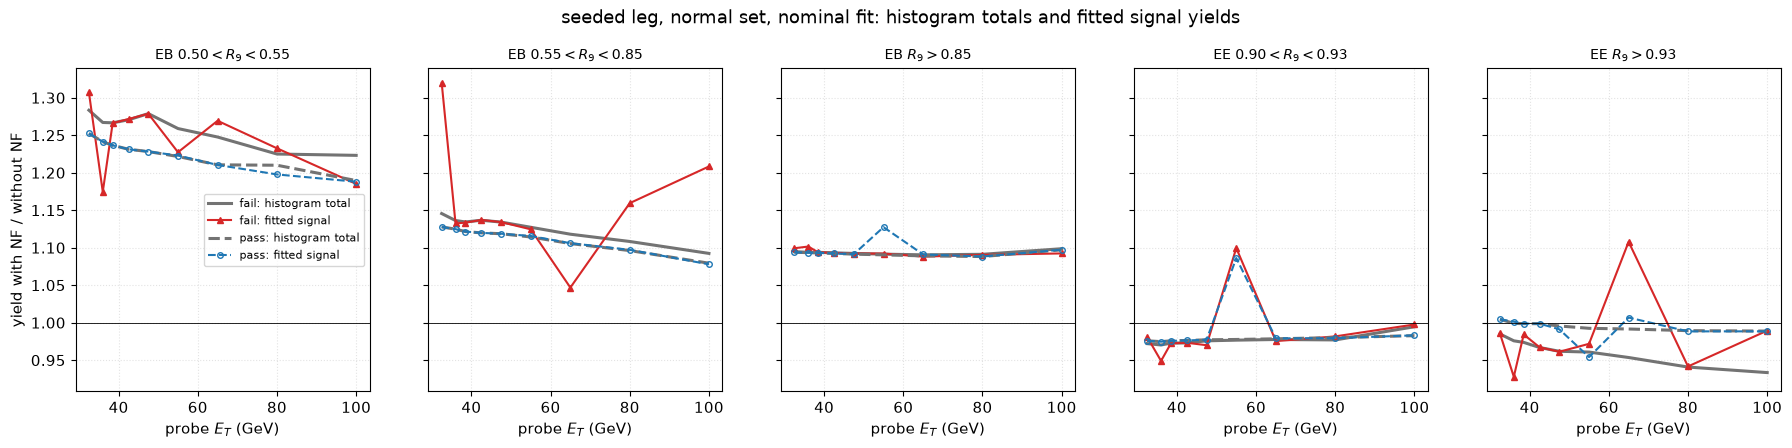

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/chain_yield_ratio_vs_pt_unseed.pdf


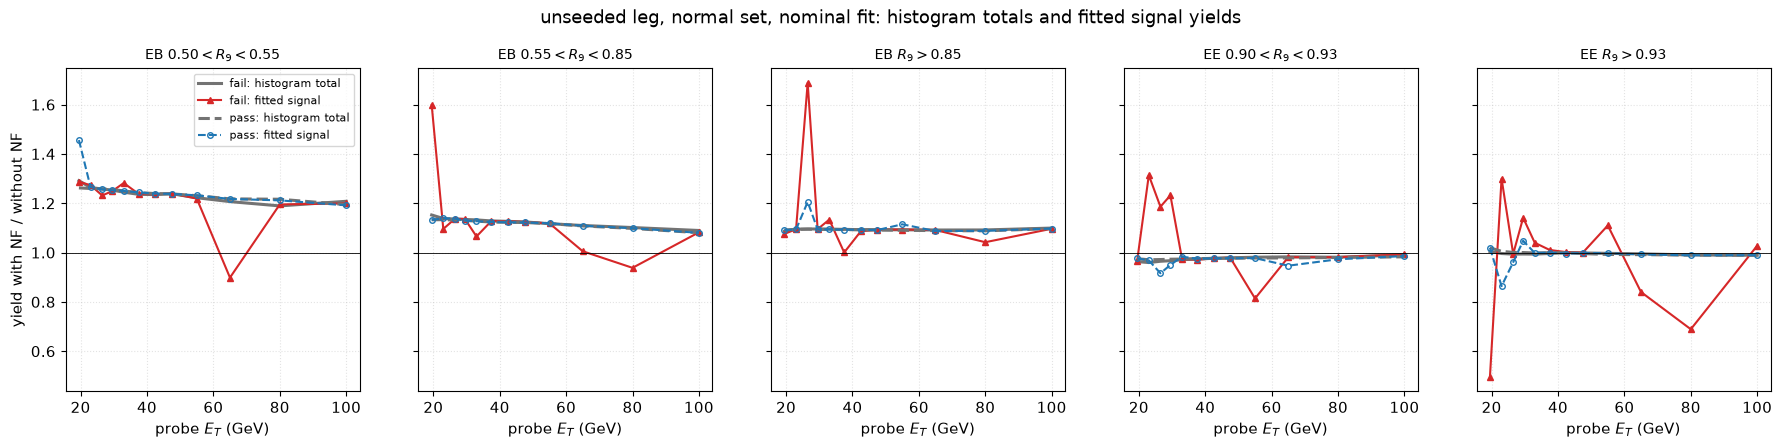

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/chain_fit_shift_vs_yield_split.pdf


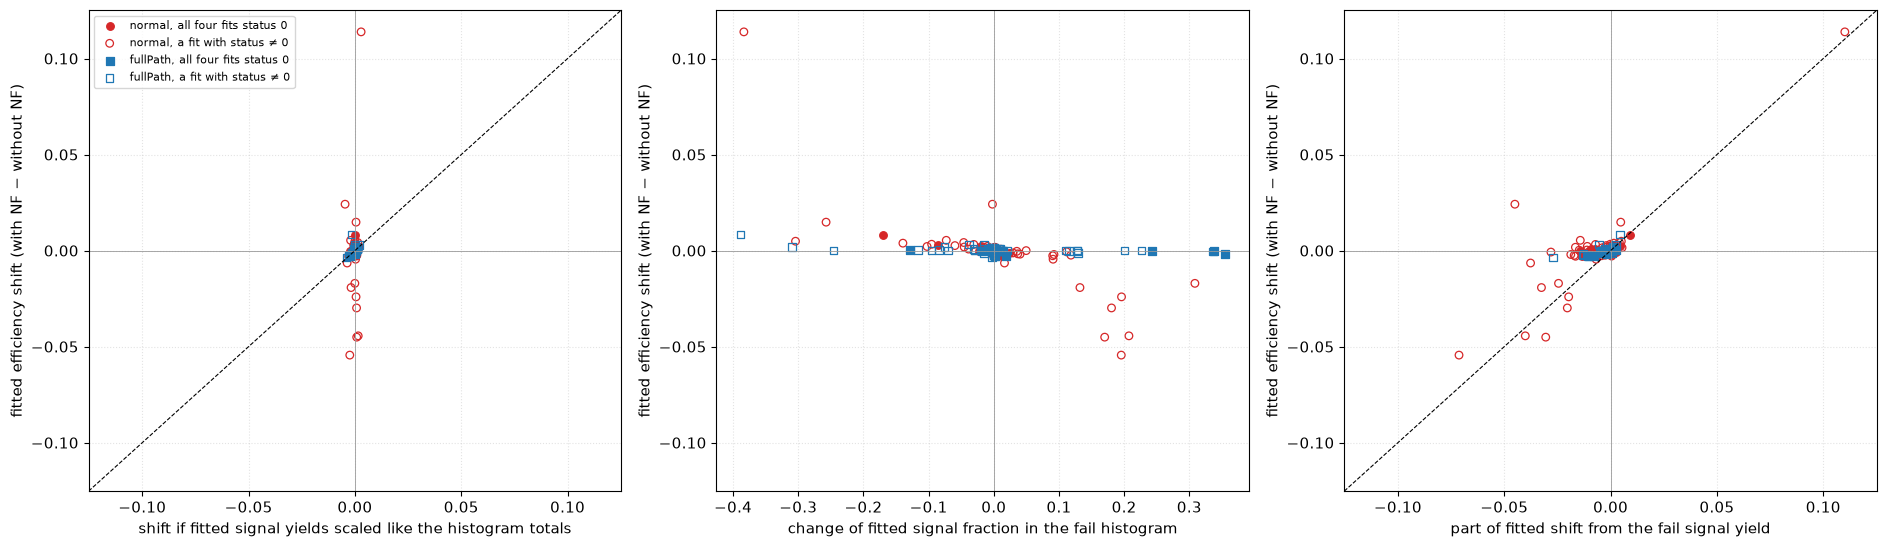

                       n  mean_abs  max_abs
set      all_status0                       
fullPath False        76   0.00067  0.00832
         True         29   0.00058  0.00303
normal   False        85   0.00561  0.11387
         True         20   0.00121  0.00822
normal set: max |rTF-1| 0.2916  max |rTP-1| 0.2623 | max |rSF-1| 0.6887  max |rSP-1| 0.4562


In [6]:
# [F] Fitted yields vs histogram totals
def wide(model):
    a = T[T.model == model].merge(HT, on=['src'] + KEY, validate='one_to_one')
    o, n = a[a.src == 'woNF'], a[a.src == 'wNF']
    D = o.merge(n, on=KEY + ['et_hi'], suffixes=('_o', '_n'), validate='one_to_one')
    assert len(D) == 210
    D['d_fit'] = D.eff_fit_n - D.eff_fit_o
    for y in ('SigP', 'SigF', 'BkgP', 'BkgF'):
        D['r' + y[0] + y[-1]] = D[f'n{y}_n'] / D[f'n{y}_o']
    D['rTP'], D['rTF'] = D.P60_n / D.P60_o, D.F60_n / D.F60_o
    D['fF_o'], D['fF_n'] = D.nSigF_o / (D.nSigF_o + D.nBkgF_o), D.nSigF_n / (D.nSigF_n + D.nBkgF_n)
    D['dfF'] = D.fF_n - D.fF_o
    D['d_scaled'] = D.nSigP_o * D.rTP / (D.nSigP_o * D.rTP + D.nSigF_o * D.rTF) - D.eff_fit_o
    D['d_fromP'] = D.nSigP_n / (D.nSigP_n + D.nSigF_o) - D.eff_fit_o
    D['d_fromF'] = D.d_fit - D.d_fromP
    D['d_sb'] = D.eff_sb_n - D.eff_sb_o
    D['all_status0'] = (D[['statusP_o', 'statusF_o', 'statusP_n', 'statusF_n']] == 0).all(axis=1)
    return D

D = wide('bwDscbCms')
DX = wide('bwDscbExp')
chk = D.merge(W[KEY + ['d_local_repo']], on=KEY)
assert (chk.d_fit - chk.d_local_repo).abs().max() < 3e-5

for leg in LEGS:
    fig, axs = plt.subplots(1, 5, figsize=(22, 4.2), sharey=True)
    for a, cat in zip(axs, CATS):
        g = D[(D.set == 'normal') & (D.leg == leg) & (D.cat == cat)].sort_values('et_lo')
        x = xpos(leg, g.et_lo.values, g.et_hi.values)
        a.plot(x, g.rTF, '-', color='0.45', lw=2.2, label='fail: histogram total')
        a.plot(x, g.rSF, '-^', color='#d62728', ms=4, label='fail: fitted signal')
        a.plot(x, g.rTP, '--', color='0.45', lw=2.2, label='pass: histogram total')
        a.plot(x, g.rSP, '--o', color='#1f77b4', ms=4, mfc='none', label='pass: fitted signal')
        a.axhline(1, color='k', lw=0.6); a.set_title(CAT_TEX[cat], fontsize=10); a.set_xlabel(r'probe $E_T$ (GeV)')
    axs[0].set_ylabel('yield with NF / without NF'); axs[0].legend(fontsize=8)
    fig.suptitle(f'{LEG_TEX[leg]} leg, normal set, nominal fit: histogram totals and fitted signal yields', y=1.02)
    save(fig, f'chain_yield_ratio_vs_pt_{leg}')
    plt.show()

fig, axs = plt.subplots(1, 3, figsize=(19, 5.6))
for a, xcol, xl in ((axs[0], 'd_scaled', 'shift if fitted signal yields scaled like the histogram totals'),
                    (axs[1], 'dfF', 'change of fitted signal fraction in the fail histogram'),
                    (axs[2], 'd_fromF', r'part of fitted shift from the fail signal yield')):
    for st, mk in (('normal', 'o'), ('fullPath', 's')):
        for ok, face in ((True, None), (False, 'none')):
            g = D[(D.set == st) & (D.all_status0 == ok)]
            a.scatter(g[xcol], g.d_fit, marker=mk, s=30, color='#d62728' if st == 'normal' else '#1f77b4', facecolors=face, lw=0.9,
                      label=f'{st}, ' + ('all four fits status 0' if ok else 'a fit with status ≠ 0'))
    a.axhline(0, color='0.6', lw=0.6); a.axvline(0, color='0.6', lw=0.6)
    a.set_xlabel(xl); a.set_ylabel('fitted efficiency shift (with NF − without NF)')
lim = D.d_fit.abs().max() * 1.1
for a in (axs[0], axs[2]):
    a.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8); a.set_ylim(-lim, lim)
axs[0].set_xlim(-lim, lim); axs[2].set_xlim(-lim, lim); axs[1].set_ylim(-lim, lim)
axs[0].legend(fontsize=8, loc='upper left')
fig.tight_layout()
save(fig, 'chain_fit_shift_vs_yield_split')
plt.show()

st0 = D.groupby(['set', 'all_status0']).d_fit.agg(n='size', mean_abs=lambda s: s.abs().mean(), max_abs=lambda s: s.abs().max()).round(5)
print(st0)
print('normal set: max |rTF-1| %.4f  max |rTP-1| %.4f | max |rSF-1| %.4f  max |rSP-1| %.4f' % tuple((D[D.set == 'normal'][c] - 1).abs().max() for c in ('rTF', 'rTP', 'rSF', 'rSP')))

## [G] Sideband-subtracted efficiency
No fit: signal window 80–100 GeV minus the two sidebands 60–70 and 110–120 GeV (same number of bins as the window), for pass and fail; ε_sb = S_pass / (S_pass + S_fail).
It is computed identically for both maps; only its **change** between maps is used (signal leaking into the sidebands biases the value itself).

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/chain_sideband_vs_fit.pdf


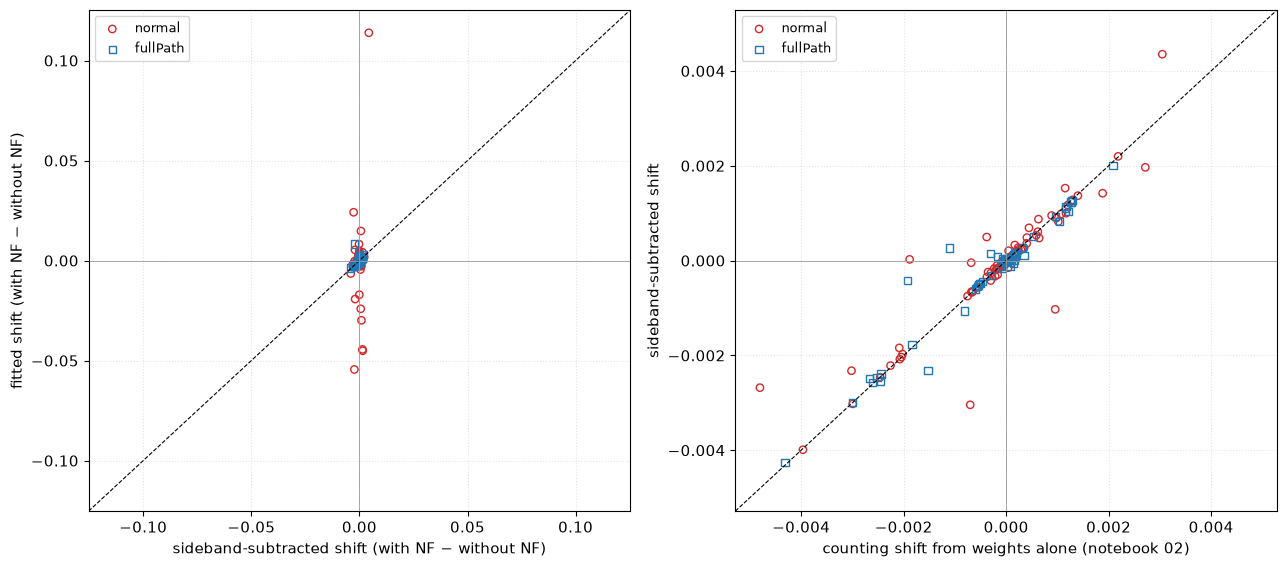

          d_count     d_sb    d_fit
set                                
fullPath  0.00432  0.00425  0.00832
normal    0.00480  0.00435  0.11387


In [7]:
# [G] Sideband-subtracted efficiency
D = D.merge(K[KEY + ['d_count']], on=KEY, validate='one_to_one')
fig, axs = plt.subplots(1, 2, figsize=(13, 5.8))
for st, mk, c in (('normal', 'o', '#d62728'), ('fullPath', 's', '#1f77b4')):
    g = D[D.set == st]
    axs[0].scatter(g.d_sb, g.d_fit, marker=mk, s=28, color=c, facecolors='none', label=st)
    axs[1].scatter(g.d_count, g.d_sb, marker=mk, s=28, color=c, facecolors='none', label=st)
lim = D.d_fit.abs().max() * 1.1
axs[0].plot([-lim, lim], [-lim, lim], 'k--', lw=0.8); axs[0].set_xlim(-lim, lim); axs[0].set_ylim(-lim, lim)
axs[0].set_xlabel('sideband-subtracted shift (with NF − without NF)'); axs[0].set_ylabel('fitted shift (with NF − without NF)')
l2 = max(D.d_sb.abs().max(), D.d_count.abs().max()) * 1.1
axs[1].plot([-l2, l2], [-l2, l2], 'k--', lw=0.8); axs[1].set_xlim(-l2, l2); axs[1].set_ylim(-l2, l2)
axs[1].set_xlabel('counting shift from weights alone (notebook 02)'); axs[1].set_ylabel('sideband-subtracted shift')
for a in axs:
    a.axhline(0, color='0.6', lw=0.6); a.axvline(0, color='0.6', lw=0.6); a.legend(fontsize=9)
fig.tight_layout()
save(fig, 'chain_sideband_vs_fit')
plt.show()
print(D.groupby('set')[['d_count', 'd_sb', 'd_fit']].agg(lambda s: s.abs().max()).round(5))

## [H] Mass-template shape
Does the map change the **shape** of the mass histogram the fitter sees? For each bin, the pass and fail histograms (60–120 GeV) are normalised to unit area and compared between maps with the total-variation distance TV = ½ Σ |p_with − p_without| (0 = identical shape, 1 = disjoint).
The six bins with the largest fitted shift are drawn: fail histogram without / with NF (normalised) and their ratio.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/chain_fail_templates_top6.pdf


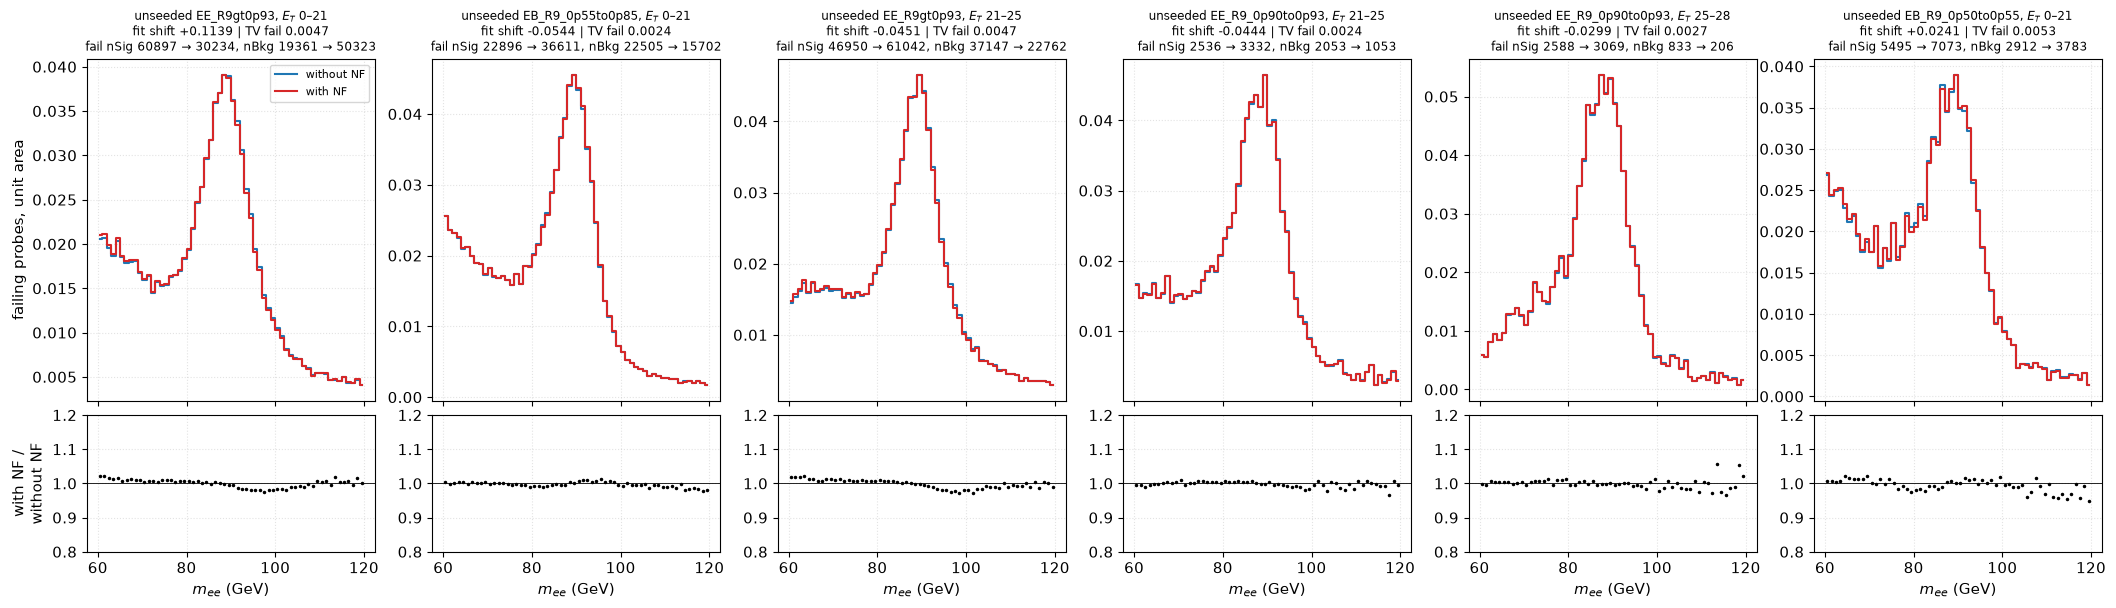

              tvP      tvF
set                       
fullPath  0.01411  0.05865
normal    0.01399  0.04267


In [8]:
# [H] Mass-template shape
FITWIN = win(60, 120)
def tv(a, b):
    a, b = a[FITWIN], b[FITWIN]
    return 0.5 * np.abs(a / a.sum() - b / b.sum()).sum()

D['tvP'] = [tv(H[('wNF', r.set, r.leg, r.cat, r.et_lo)][0], H[('woNF', r.set, r.leg, r.cat, r.et_lo)][0]) for r in D.itertuples()]
D['tvF'] = [tv(H[('wNF', r.set, r.leg, r.cat, r.et_lo)][1], H[('woNF', r.set, r.leg, r.cat, r.et_lo)][1]) for r in D.itertuples()]

top = D[D.set == 'normal'].reindex(D[D.set == 'normal'].d_fit.abs().sort_values(ascending=False).index).head(6)
fig, axs = plt.subplots(2, 6, figsize=(26, 6.4), sharex=True, gridspec_kw={'height_ratios': [3, 1.2], 'hspace': 0.06})
for j, r in enumerate(top.itertuples()):
    fo, fn = H[('woNF', r.set, r.leg, r.cat, r.et_lo)][1][FITWIN], H[('wNF', r.set, r.leg, r.cat, r.et_lo)][1][FITWIN]
    axs[0, j].step(CEN[FITWIN], fo / fo.sum(), where='mid', color=COL['woNF'], label=LAB['woNF'])
    axs[0, j].step(CEN[FITWIN], fn / fn.sum(), where='mid', color=COL['wNF'], label=LAB['wNF'])
    with np.errstate(divide='ignore', invalid='ignore'):
        axs[1, j].plot(CEN[FITWIN], (fn / fn.sum()) / (fo / fo.sum()), '.', color='k', ms=3)
    axs[1, j].axhline(1, color='k', lw=0.6); axs[1, j].set_ylim(0.8, 1.2); axs[1, j].set_xlabel(r'$m_{ee}$ (GeV)')
    hi = r.et_hi if r.et_hi < 1e5 else np.inf
    axs[0, j].set_title(f'{LEG_TEX[r.leg]} {r.cat}, $E_T$ {r.et_lo:g}–{hi:g}\nfit shift {r.d_fit:+.4f} | TV fail {r.tvF:.4f}\n'
                        f'fail nSig {r.nSigF_o:.0f} → {r.nSigF_n:.0f}, nBkg {r.nBkgF_o:.0f} → {r.nBkgF_n:.0f}', fontsize=8.5)
axs[0, 0].set_ylabel('failing probes, unit area'); axs[1, 0].set_ylabel('with NF /\nwithout NF'); axs[0, 0].legend(fontsize=8)
save(fig, 'chain_fail_templates_top6')
plt.show()
print(D.groupby('set')[['tvP', 'tvF']].max().round(5))

## [I] Map change per fitter bin
From the per-cell probe counts of notebook 01 (60 < m < 120 GeV). For pass and fail probes of each fitter bin:
- `mP`, `mF`: mean map change = weighted yield with NF / without NF;
- `sF`: spread of the per-cell ratio w_with / w_without over the failing probes (weighted by the without-NF yield);
- `dlog = ln(mP / mF)`: how differently the map moves pass and fail — the only way the map can move a counting efficiency.

These are scattered against the size of the fitted shift.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/chain_map_change_vs_fit_shift.pdf


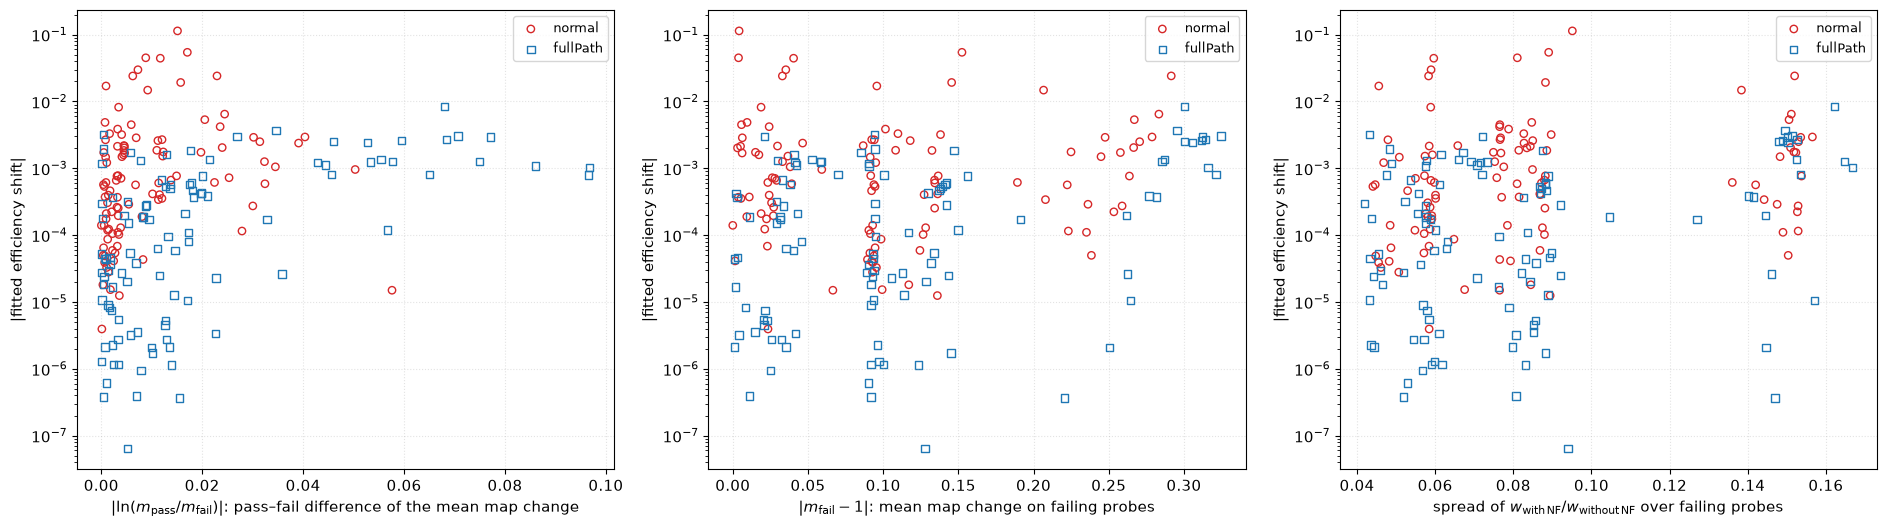

In [9]:
# [I] Map change per fitter bin
Z = np.load(DATA / 'cell_counts.npz')
MO, MN = Z['map_old'].ravel(), Z['map_new'].ravel()
mrows = []
for st in SETDIR:
    for leg in LEGS:
        for cat in CATS:
            k = f'{leg}__{st}__{cat}'; pt = Z['pt__' + k]; n = Z['counts__' + k][:len(pt) - 1].astype(float)   # (pT bin, fail/pass, cell)
            for ib in range(len(pt) - 1):
                nf, np_ = n[ib, 0], n[ib, 1]
                Po, Pn, Fo, Fn = (np_ * MO).sum(), (np_ * MN).sum(), (nf * MO).sum(), (nf * MN).sum()
                ratio = np.divide(MN, MO, out=np.ones_like(MN), where=MO > 0)
                sF = np.sqrt(((nf * MO) * (ratio - Fn / Fo) ** 2).sum() / Fo)
                mrows.append(dict(set=st, leg=leg, cat=cat, et_lo=float(pt[ib]), mP=Pn / Po, mF=Fn / Fo, sF=sF, dlog=np.log((Pn / Po) / (Fn / Fo))))
M = pd.DataFrame(mrows)
D = D.merge(M, on=KEY, validate='one_to_one')
assert np.allclose(D.mF, D.rTF, rtol=1e-4) and np.allclose(D.mP, D.rTP, rtol=1e-4)      # same quantities as the fitter-histogram ratios of [F]

fig, axs = plt.subplots(1, 3, figsize=(19, 5.4))
for a, xcol, xl in ((axs[0], 'dlog', r'$|\ln(m_{\rm pass}/m_{\rm fail})|$: pass–fail difference of the mean map change'),
                    (axs[1], 'mF', r'$|m_{\rm fail}-1|$: mean map change on failing probes'),
                    (axs[2], 'sF', r'spread of $w_{\rm with\,NF}/w_{\rm without\,NF}$ over failing probes')):
    for st, mk, c in (('normal', 'o', '#d62728'), ('fullPath', 's', '#1f77b4')):
        g = D[D.set == st]
        xv = g[xcol].abs() if xcol == 'dlog' else ((g[xcol] - 1).abs() if xcol == 'mF' else g[xcol])
        a.scatter(xv, g.d_fit.abs(), marker=mk, s=28, color=c, facecolors='none', label=st)
    a.set_xlabel(xl); a.set_ylabel('|fitted efficiency shift|'); a.set_yscale('log'); a.legend(fontsize=9)
fig.tight_layout()
save(fig, 'chain_map_change_vs_fit_shift')
plt.show()

## [J] Chain table and numbers for the slides
Every number quoted on the new slides is written to `data/slide_numbers_03.json`.

In [10]:
# [J] Chain table and numbers for the slides
D.drop(columns=[c for c in D.columns if c.startswith('bin_') or c.startswith('src_') or c.startswith('model_')]).to_csv(DATA / 'map_to_fit_chain.csv', index=False, float_format='%.6g')
T.to_csv(DATA / 'fit_yields.csv', index=False, float_format='%.8g')
S = {}
for st in SETDIR:
    g = D[D.set == st]
    S[st] = dict(
        n_bins=len(g),
        max_abs_d_fit=g.d_fit.abs().max(), max_abs_d_count=g.d_count.abs().max(), max_abs_d_sb=g.d_sb.abs().max(), max_abs_d_scaled=g.d_scaled.abs().max(),
        max_abs_rTF_m1=(g.rTF - 1).abs().max(), max_abs_rTP_m1=(g.rTP - 1).abs().max(), max_abs_rSF_m1=(g.rSF - 1).abs().max(), max_abs_rSP_m1=(g.rSP - 1).abs().max(),
        max_tvF=g.tvF.max(), max_tvP=g.tvP.max(), max_abs_dfF=g.dfF.abs().max(),
        corr_fit_scaled=corr(g.d_fit, g.d_scaled), corr_fit_sb=corr(g.d_fit, g.d_sb), corr_sb_count=corr(g.d_sb, g.d_count),
        corr_fit_dfF=corr(g.d_fit, g.dfF), corr_fit_fromF=corr(g.d_fit, g.d_fromF),
        spearman_absfit_absdlog=corr(g.d_fit.abs(), g.dlog.abs(), 'spearman'), spearman_absfit_mF=corr(g.d_fit.abs(), (g.mF - 1).abs(), 'spearman'),
        spearman_absfit_sF=corr(g.d_fit.abs(), g.sF, 'spearman'), spearman_absfit_tvF=corr(g.d_fit.abs(), g.tvF, 'spearman'),
        n_all_status0=int(g.all_status0.sum()), n_not_all_status0=int((~g.all_status0).sum()),
        mean_abs_d_fit_all_status0=g[g.all_status0].d_fit.abs().mean(), mean_abs_d_fit_not_all_status0=g[~g.all_status0].d_fit.abs().mean(),
        max_abs_d_fit_all_status0=g[g.all_status0].d_fit.abs().max(), max_abs_d_fit_not_all_status0=g[~g.all_status0].d_fit.abs().max(),
        n_abs_d_fit_gt_0p01=int((g.d_fit.abs() > 0.01).sum()), n_abs_d_fit_gt_0p01_not_all_status0=int(((g.d_fit.abs() > 0.01) & ~g.all_status0).sum()),
        n_abs_d_sb_gt_0p01=int((g.d_sb.abs() > 0.01).sum()))
S['fit_status'] = Q.to_dict(orient='records')
S['status_values'] = dict(passing=sorted(int(v) for v in T.statusP.unique()), failing=sorted(int(v) for v in T.statusF.unique()),
                          covQual=sorted(int(v) for v in set(T.covQualP) | set(T.covQualF)))
S['validation'] = dict(max_abs_eff_parsed_minus_published=dmax.to_dict(), max_rel_hist_vs_cells_pass=float(relP), max_rel_hist_vs_cells_fail=float(relF))
(DATA / 'slide_numbers_03.json').write_text(json.dumps(S, indent=1, default=float))
for f in ('map_to_fit_chain.csv', 'fit_yields.csv', 'slide_numbers_03.json'):
    print(DATA / f)
print(json.dumps({k: {a: (round(b, 5) if isinstance(b, float) else b) for a, b in v.items()} for k, v in S.items() if k in SETDIR}, indent=1))

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/map_to_fit_chain.csv
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/fit_yields.csv
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/slide_numbers_03.json
{
 "normal": {
  "n_bins": 105,
  "max_abs_d_fit": 0.11387,
  "max_abs_d_count": 0.0048,
  "max_abs_d_sb": 0.00435,
  "max_abs_d_scaled": 0.00464,
  "max_abs_rTF_m1": 0.29155,
  "max_abs_rTP_m1": 0.26227,
  "max_abs_rSF_m1": 0.68869,
  "max_abs_rSP_m1": 0.45617,
  "max_tvF": 0.04267,
  "max_tvP": 0.01399,
  "max_abs_dfF": 0.38346,
  "corr_fit_scaled": 0.18303,
  "corr_fit_sb": 0.28462,
  "corr_sb_count": 0.91371,
  "corr_fit_dfF": -0.75411,
  "corr_fit_fromF": 0.82651,
  "spearman_absfit_absdlog": 0.45626,
  "spearman_absfit_mF": 0.03182,
  "spearman_absfit_sF": 0.25967,
  "spearman_absfit_tvF": 0.21045,
  "n_all_status0": 20,
  "n_not_all_status0": 85,
  "mean_abs_d_fit_all_status